## 地面磁发射机分析

这一段的分析将基于Ansys Maxwell的磁场仿真结果，和理论仿真计算进行联合分析计算。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from magcomm.coil import *
from magcomm.const import Const

tx_coil_default = OGCoil(towards='y', phi_axis='x')
print(f"线圈的电阻为: {tx_coil_default.resistance:.6f} Ω")
print(f"线圈的磁矩为: {tx_coil_default.mag_moment:.6f} A·m²")
print(f"线圈的电感为: {tx_coil_default.inductance:.6f} H")
print(f"线圈的电感是否有效: {tx_coil_default.inductance_valid}")

线圈的电阻为: 0.086304 Ω
线圈的磁矩为: 640.884901 A·m²
线圈的电感为: 0.257715 H
线圈的电感是否有效: False


### 发射线圈的磁场分析

首先我们根据基本公式

$
B_r=\frac{\mu_0}{2\pi}\frac{m_{tx}\cos{(\theta)}}{d^3} \\
B_{\theta}=\frac{\mu_0}{4\pi}\frac{m_{tx}\sin{(\theta)}}{d^3}
$

计算在某一条特定曲线下的磁感应强度，并且和Ansys Maxwell的仿真结果进行对比。

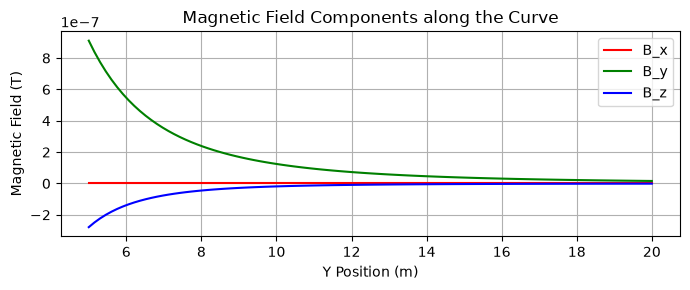

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000000	| 1.707728e-23	| 9.110511e-07	| -2.788932e-07	|
|6.666667	| 5.637530e-24	| 4.045871e-07	| -9.206786e-08	|
|8.333333	| 2.355505e-24	| 2.121741e-07	| -3.846832e-08	|
|10.000000	| 1.148362e-24	| 1.244027e-07	| -1.875417e-08	|
|11.666667	| 6.239464e-25	| 7.896301e-08	| -1.018982e-08	|
|13.333333	| 3.673136e-25	| 5.317169e-08	| -5.998687e-09	|
|15.000000	| 2.299865e-25	| 3.747618e-08	| -3.755964e-09	|
|16.666667	| 1.512117e-25	| 2.738922e-08	| -2.469475e-09	|
|18.333333	| 1.034406e-25	| 2.061644e-08	| -1.689313e-09	|
|20.000000	| 7.312253e-26	| 1.590252e-08	| -1.194182e-09	|


In [3]:
# 设定曲线为(0, 5, -1)到(0, 20, -1)，计算沿着曲线的磁场强度
points = np.array([[0, y, -1] for y in np.linspace(5, 20, 100)])
b_field = tx_coil_default.calculate_magnetic_field(points)

# 沿着曲线绘制x, y, z方向（一张图内）的磁感应强度
plt.figure(figsize=(7, 3))
plt.plot(points[:, 1], b_field[:, 0], label='B_x', color='r')
plt.plot(points[:, 1], b_field[:, 1], label='B_y', color='g')
plt.plot(points[:, 1], b_field[:, 2], label='B_z', color='b')
plt.title('Magnetic Field Components along the Curve')
plt.xlabel('Y Position (m)')
plt.ylabel('Magnetic Field (T)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# 5~20m 平均切分10个点，计算每个点的磁场强度，并且打印一个表格
points_table = np.linspace(5, 20, 10)
print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for y in points_table:
    b_field = tx_coil_default.calculate_magnetic_field(np.array([0, y, -1]))
    print(f"|{y:.6f}\t| {b_field[0]:.6e}\t| {b_field[1]:.6e}\t| {b_field[2]:.6e}\t|")

Maxwell在上述坐标下计算的磁感应强度为：

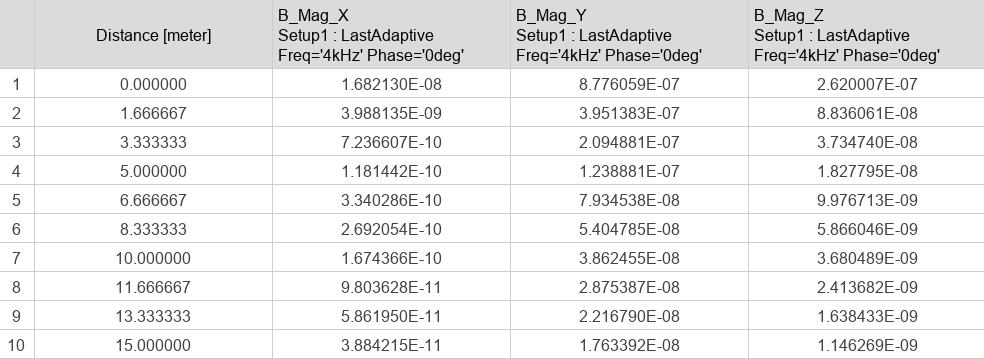

计算结果基本准确，误差在5%之内。因此自由空间内的磁场计算公式是可以使用的。

### 带土壤环境的发射线圈磁场分析

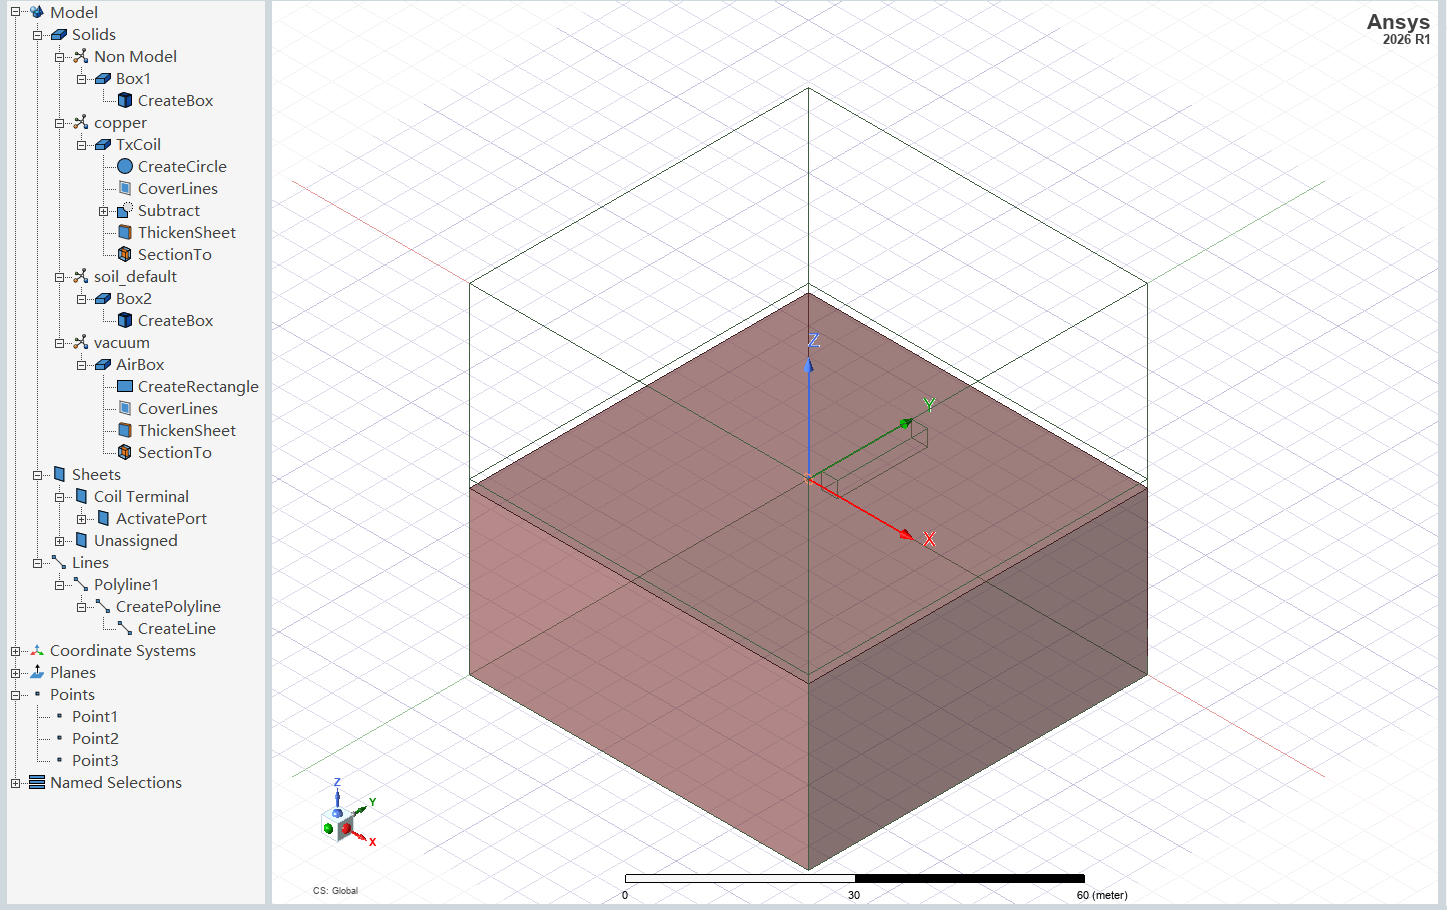

如图所示，发射线圈的下方被放置了土壤区域，并且将观察线放置在了(0, 5, -12)到(0, 20, -12)的直线上。我们首先通过自由空间的磁场强度计算公式推导这些点的磁感应强度，然后和Maxwell的仿真结果进行对比。

之所以选择更深的土壤区域，是因为在浅层土壤中，磁场的影响不大，而在深层土壤中，磁场的影响会更加明显。我们对比了自由空间的磁场计算结果、Maxwell在土壤环境下的仿真结果、以及Maxwell在自由空间下的仿真结果。

土壤的参数如下：
| 参数 | 数值 |
| --- | --- |
| 相对磁导率 | 1 |
| 电导率 | 0.005 S/m |
| 介电常数 | 10 |

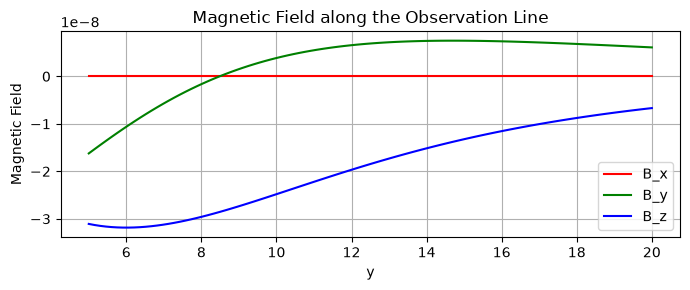

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000000	| 1.902465e-24	| -1.622524e-08	| -3.106961e-08	|
|6.666667	| 1.932030e-24	| -7.245375e-09	| -3.155244e-08	|
|8.333333	| 1.768764e-24	| -4.921338e-10	| -2.888612e-08	|
|10.000000	| 1.519109e-24	| 3.859166e-09	| -2.480893e-08	|
|11.666667	| 1.255117e-24	| 6.257740e-09	| -2.049762e-08	|
|13.333333	| 1.014173e-24	| 7.299857e-09	| -1.656270e-08	|
|15.000000	| 8.101935e-25	| 7.497829e-09	| -1.323146e-08	|
|16.666667	| 6.444703e-25	| 7.219370e-09	| -1.052500e-08	|
|18.333333	| 5.128029e-25	| 6.702585e-09	| -8.374706e-09	|
|20.000000	| 4.093513e-25	| 6.090972e-09	| -6.685214e-09	|


In [4]:
points = np.array([[0, y, -12] for y in np.linspace(5, 20, 100)])

b_field = tx_coil_default.calculate_magnetic_field(points)

plt.figure(figsize=(7, 3))
plt.plot(points[:, 1], b_field[:, 0], label='B_x', color='r')
plt.plot(points[:, 1], b_field[:, 1], label='B_y', color='g')
plt.plot(points[:, 1], b_field[:, 2], label='B_z', color='b')
plt.xlabel('y')
plt.ylabel('Magnetic Field')
plt.title('Magnetic Field along the Observation Line')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for y in np.linspace(5, 20, 10):
    b_field = tx_coil_default.calculate_magnetic_field(np.array([0, y, -12]))
    print(f"|{y:.6f}\t| {b_field[0]:.6e}\t| {b_field[1]:.6e}\t| {b_field[2]:.6e}\t|")

Maxwell在上述坐标下计算的磁感应强度为：

带土壤的Maxwell仿真结果：

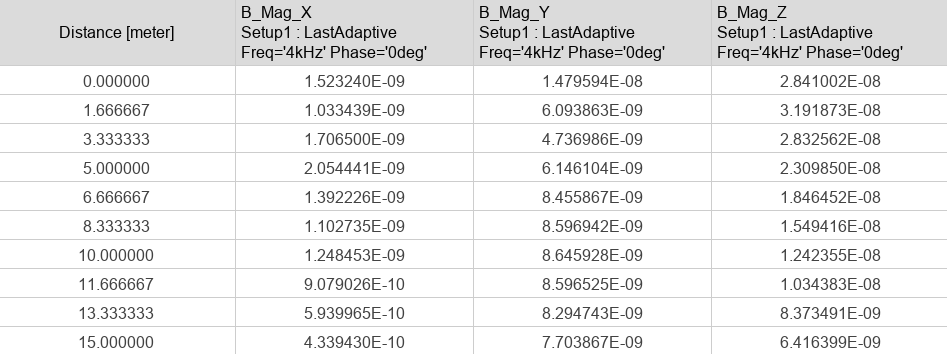

不带土壤的Maxwell仿真结果：

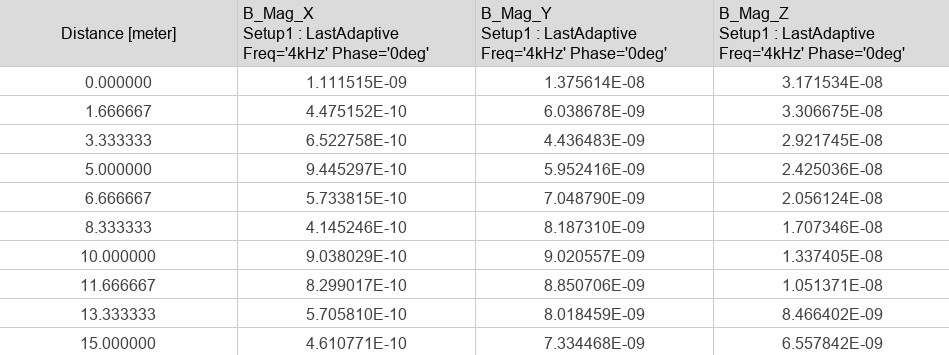

同样的，二者的误差在5%到10%之间，这说明了土壤环境对磁场的影响是有限的。但是不可否认的是，如果距离拉伸到200米以上，交变磁场穿过土壤的磁感线会更多，因此土壤的影响会更加明显。

### 土壤对线圈电感的影响

我们改变土壤到线圈的距离（线圈距离地面的高度），线圈的平面垂直于土壤平面，并且通过Maxwell的Winding端口仿真结果获取相同线圈在自由空间和有土壤环境下的电感值，测试频率4kHz，结果如下：

| 高度（m） | 电阻（mOhm） | 电感（mH） |
| --- | --- | --- |
| 1 | 89.2829 | 3.6797 |
| 1.5 | 89.3066 | 3.6766 |
| 2 | 89.2600 | 3.6778 |
| N/A | 89.1985 | 3.6755 |

上述的结果表明，土壤对线圈的电感影响不大，电感值的变化在0.1%以内，因此不用担心线圈平面和土壤平面垂直状态下，土壤对线圈的电感影响过大。


### 线圈平躺的情况

上述分析的是线圈立起来的情况：

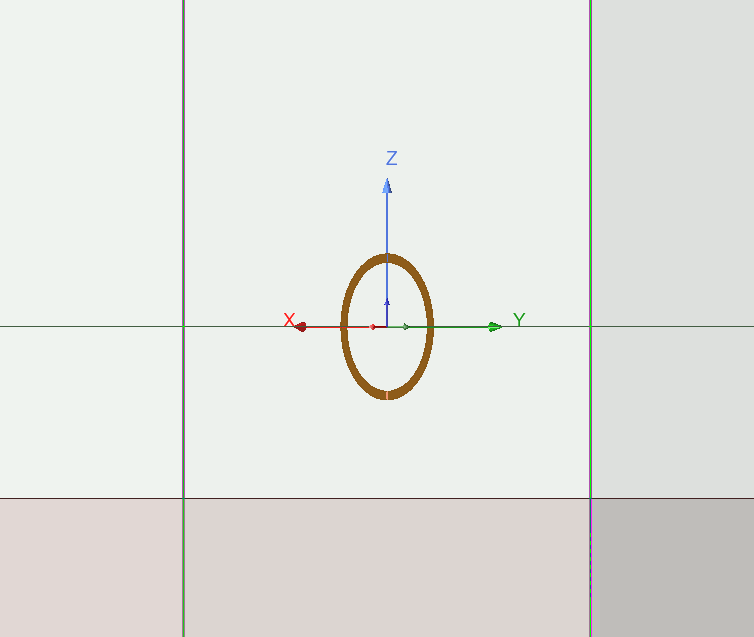

现在分析线圈平躺的情况：

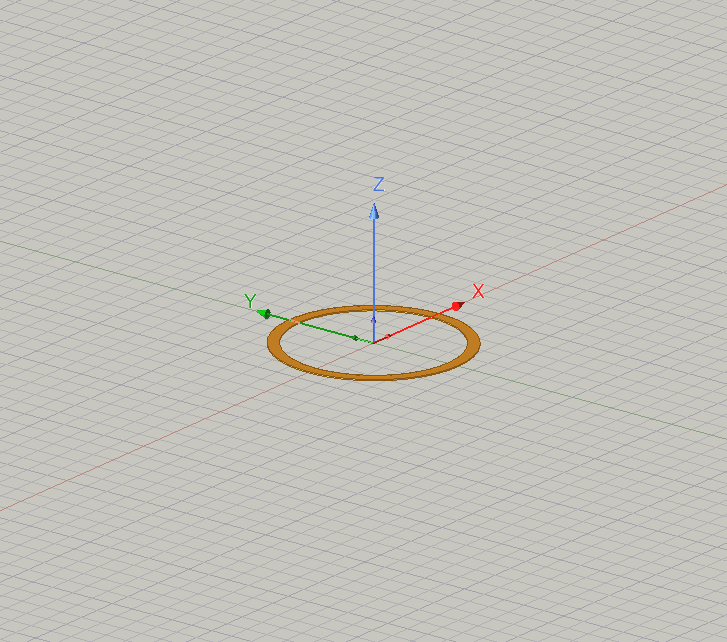

在前面的计算中，线圈的平面垂直于土壤平面，而实际上雷管的线圈平面是平行于地面的，因此实际上在目标区域内，能够有效穿过雷管线圈的磁感线可能相当有限，尤其是雷管到线圈的水平距离远大于垂直距离。因此我们考虑了线圈平躺的情况，线圈的平面和土壤平面平行，并重新进行上述的仿真和计算，其中求解的线为(0, 5, -1)到(0, 20, -1)的直线。

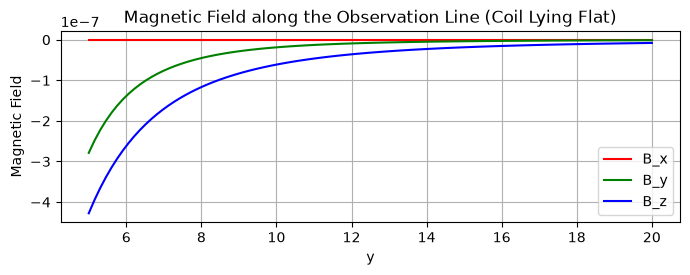

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000000	| -1.707728e-23	| -2.788932e-07	| -4.276362e-07	|
|6.666667	| -5.637530e-24	| -9.206786e-08	| -1.953885e-07	|
|8.333333	| -2.355505e-24	| -3.846832e-08	| -1.037790e-07	|
|10.000000	| -1.148362e-24	| -1.875417e-08	| -6.126362e-08	|
|11.666667	| -6.239464e-25	| -1.018982e-08	| -3.904480e-08	|
|13.333333	| -3.673136e-25	| -5.998687e-09	| -2.636090e-08	|
|15.000000	| -2.299865e-25	| -3.755964e-09	| -1.861289e-08	|
|16.666667	| -1.512117e-25	| -2.469475e-09	| -1.362053e-08	|
|18.333333	| -1.034406e-25	| -1.689313e-09	| -1.026215e-08	|
|20.000000	| -7.312253e-26	| -1.194182e-09	| -7.921404e-09	|


In [5]:
tx_coil_default = OGCoil()

points = np.array([[0, y, -1] for y in np.linspace(5, 20, 100)])
b_field = tx_coil_default.calculate_magnetic_field(points)

plt.figure(figsize=(7, 3))
plt.plot(points[:, 1], b_field[:, 0], label='B_x', color='r')
plt.plot(points[:, 1], b_field[:, 1], label='B_y', color='g')
plt.plot(points[:, 1], b_field[:, 2], label='B_z', color='b')
plt.xlabel('y')
plt.ylabel('Magnetic Field')
plt.title('Magnetic Field along the Observation Line (Coil Lying Flat)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for y in np.linspace(5, 20, 10):
    b_field = tx_coil_default.calculate_magnetic_field(np.array([0, y, -1]))
    print(f"|{y:.6f}\t| {b_field[0]:.6e}\t| {b_field[1]:.6e}\t| {b_field[2]:.6e}\t|")

性能很明显的要好了不少（大约有一个7倍的增益），因此线圈平躺确实是一个不错的选择。我们再对比一下在Maxwell中仿真得到的磁感应强度：

没有土壤的情况：

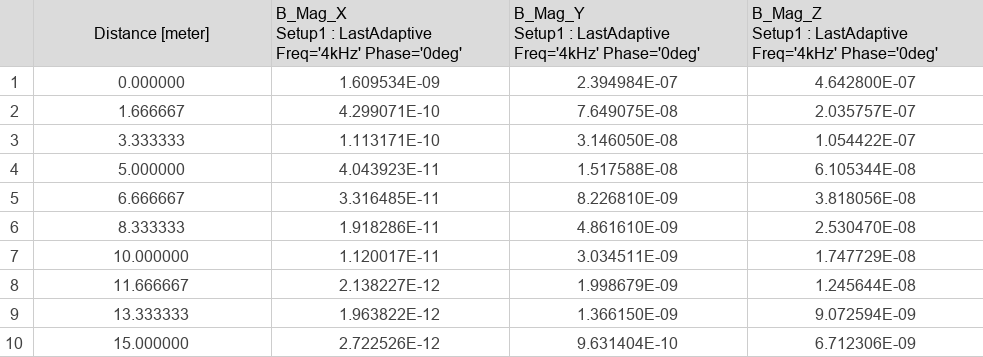

带有土壤的情况（土壤距离线圈中心点为0.8米）：

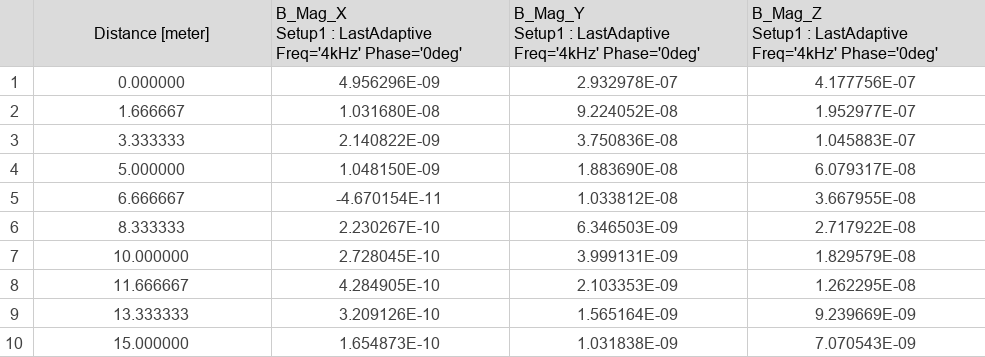

有一定的计算偏差，这可能和Maxwell的仿真边界条件的设置（Maxwell 3D没有开放边界条件）有关。但是总体来说，线圈平躺的情况确实是一个不错的选择，尤其是雷管到线圈的水平距离远大于垂直距离的情况下。

那么接下来讨论如果线圈平躺，那么是否会存在电感偏移的问题。

| 高度（m） | 电阻（mOhm） | 电感（mH） |
| --- | --- | --- |
| 0.5 | 89.4864 | 3.6733 |
| 1 | 89.3349 | 3.6721 |
| 1.5 | 89.2878 | 3.6719 | 
| N/A | 89.1985 | 3.6755 |

可见线圈平躺以后，土壤对线圈的电感影响仍然不大，电感值的变化在0.1%以内。

### 实际距离磁场计算

上述的分析说明了直接使用自由空间的磁场计算公式在土壤导电性不高（电导率小于0.005 S/m）的情况下，可以得到比较准确的结果。因此我们直接使用自由空间的磁场计算公式，计算在实际工作距离下的磁场强度，并且使用该计算结果来分析雷管的磁场接收情况。

In [6]:
# 平躺线圈
points = np.array([[0, y, -10] for y in [200, 250, 300]])
tx_coil_default.towards = 'z'
b_field = tx_coil_default.calculate_magnetic_field(points)
h_field = b_field / Const.mu0
print("Tx Coil Lying Flat")
print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for idx in range(len(points)):
    print(f"|{points[idx]}\t| {b_field[idx, 0]:.6e}\t| {b_field[idx, 1]:.6e}\t| {b_field[idx, 2]:.6e}\t|")
print()
print("|Position (m)\t| H_x (A/m)\t| H_y (A/m)\t| H_z (A/m)\t|")
print("|------------\t|----------\t|----------\t|----------\t|")
for idx in range(len(points)):
    print(f"|{points[idx]}\t| {h_field[idx, 0]:.6e}\t| {h_field[idx, 1]:.6e}\t| {h_field[idx, 2]:.6e}\t|")

tx_coil_default.towards = 'y'
b_field = tx_coil_default.calculate_magnetic_field(points)
h_field = b_field / Const.mu0
print("\nTx Coil Standing Up")
print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for idx in range(len(points)):
    print(f"|{points[idx]}\t| {b_field[idx, 0]:.6e}\t| {b_field[idx, 1]:.6e}\t| {b_field[idx, 2]:.6e}\t|")
print()
print("|Position (m)\t| H_x (A/m)\t| H_y (A/m)\t| H_z (A/m)\t|")
print("|------------\t|----------\t|----------\t|----------\t|")
for idx in range(len(points)):
    print(f"|{points[idx]}\t| {h_field[idx, 0]:.6e}\t| {h_field[idx, 1]:.6e}\t| {h_field[idx, 2]:.6e}\t|")

Tx Coil Lying Flat
|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|[  0 200 -10]	| -7.312253e-29	| -1.194182e-12	| -7.921404e-12	|
|[  0 250 -10]	| -3.001832e-29	| -4.902363e-13	| -4.072230e-12	|
|[  0 300 -10]	| -1.449411e-29	| -2.367067e-13	| -2.361807e-12	|

|Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m)	|
|------------	|----------	|----------	|----------	|
|[  0 200 -10]	| -5.818906e-23	| -9.502995e-07	| -6.303653e-06	|
|[  0 250 -10]	| -2.388782e-23	| -3.901177e-07	| -3.240577e-06	|
|[  0 300 -10]	| -1.153404e-23	| -1.883652e-07	| -1.879466e-06	|

Tx Coil Standing Up
|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|[  0 200 -10]	| 7.312253e-29	| 1.590252e-11	| -1.194182e-12	|
|[  0 250 -10]	| 3.001832e-29	| 8.164069e-12	| -4.902363e-13	|
|[  0 300 -10]	| 1.449411e-29	| 4.731504e-12	| -2.367067e-13	|

|Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m)	|
|------------	|----------	|----------	|

## 多地面发射机的分析

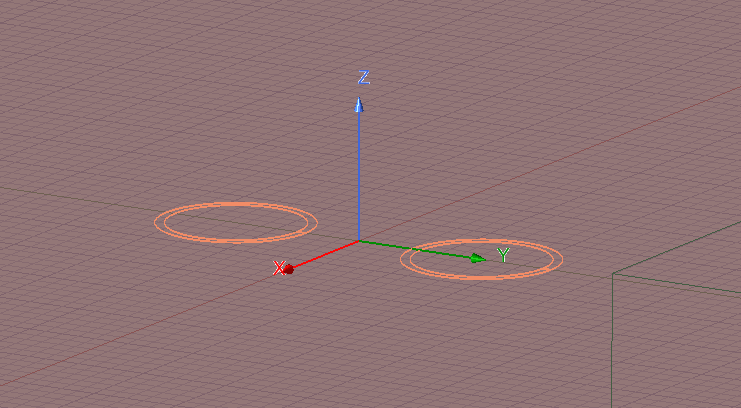

考虑如图所示的双线圈结构，理论上来说如果能够保证两个线圈的磁场相位一致，那么在雷管接收线圈的磁场强度将会有一个2倍的增益。双线圈的磁场分析是比较复杂的，因此针对远场，我们直接将两个线圈引发的磁场强度进行叠加。

假定两个线圈之间的距离是2.5米，分别计算两个线圈在雷管接收线圈位置的磁场强度：

In [7]:
og_coil = OGCoil()
coil_distance = 2.5

tx_coil_1 = OGCoil(towards='z', center_position=[coil_distance/2, 0, 0])
tx_coil_2 = OGCoil(towards='z', center_position=[-coil_distance/2, 0, 0])
points = np.array([[0, y, -1] for y in np.linspace(5, 20, 10)])

b_field_1 = tx_coil_1.calculate_magnetic_field(points)
b_field_2 = tx_coil_2.calculate_magnetic_field(points)
b_total = b_field_1 + b_field_2

print("\nTwo Coils Laying Flat")
print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for i in range(len(points)):
    print(f"|{points[i, 1]:.3f}\t\t| {b_total[i, 0]:.6e}\t| {b_total[i, 1]:.6e}\t| {b_total[i, 2]:.6e}\t|")



Two Coils Laying Flat
|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000		| 2.646978e-23	| -4.820641e-07	| -7.893799e-07	|
|6.667		| 6.617445e-24	| -1.692135e-07	| -3.723284e-07	|
|8.333		| 3.308722e-24	| -7.283063e-08	| -2.010328e-07	|
|10.000		| -2.481542e-24	| -3.609606e-08	| -1.197938e-07	|
|11.667		| 8.271806e-25	| -1.981041e-08	| -7.679286e-08	|
|13.333		| -7.237830e-25	| -1.173919e-08	| -5.204579e-08	|
|15.000		| -4.135903e-25	| -7.383645e-09	| -3.684644e-08	|
|16.667		| 2.584939e-25	| -4.870419e-09	| -2.701527e-08	|
|18.333		| 1.680211e-25	| -3.339791e-09	| -2.038327e-08	|
|20.000		| 1.163223e-25	| -2.365255e-09	| -1.575112e-08	|


Maxwell的仿真结果为：

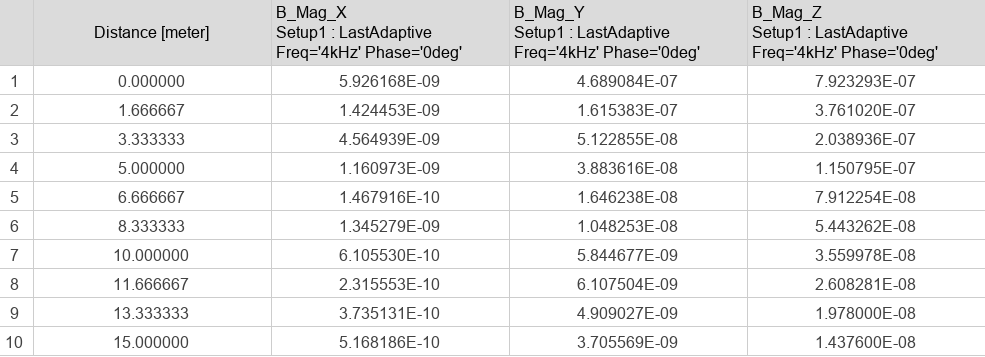

同样的，在较近的距离内，两个线圈的磁场强度叠加的结果和Maxwell的仿真结果基本一致。距离较远时靠近了仿真的边界，由于边界条件的问题，仿真结果偏小。

这说明了使用双线圈的发射机确实可以在远距离下提高雷管接收线圈的磁场强度。但是我们不能忽视两个线圈之间的互感，这可能导致驱动电路上存在一定的问题。使用Windings端口提取两个线圈端口的互阻抗：

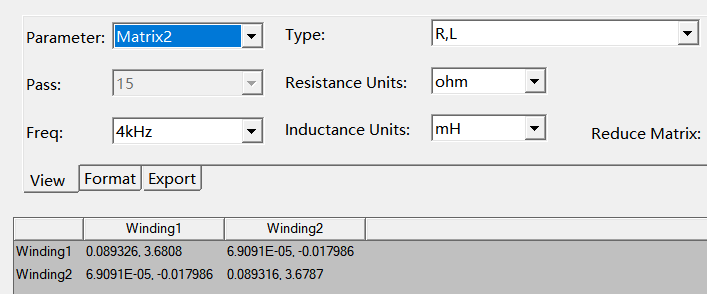

自感几乎没有变化，而互感仅为17uH，远小于自感。

总的来说，使用双线圈的发射机确实可以在远距离下提高雷管接收线圈的磁场强度，但是需要注意两个线圈之间的互感问题。后续的分析中我们暂时不考虑双线圈的激励，仍然从单线圈的发射机出发，分析雷管接收线圈的磁场接收情况。多线圈的发射机分析暂时按照简单的叠加方式（乘以2）处理。

## 雷管地下磁发射机分析

### 发射线圈的磁场分析

同样的，我们可以通过类似的分析方法来研究雷管在地下环境中的磁发射特性。

In [8]:
ug_coil_default = UGCoil()
print(f"接收线圈的电阻为: {ug_coil_default.resistance:.6f} Ω")
print(f"接收线圈的有效磁导率为: {ug_coil_default.mu_eff:.6f}")
print(f"接收线圈的有效面积为: {ug_coil_default.area_eff:.6f} m²")
print(f"接收线圈的磁矩为: {ug_coil_default.mag_moment:.6f} A·m²")
print(f"接收线圈的电感为: {ug_coil_default.inductance:.6e} H")

接收线圈的电阻为: 2.520682 Ω
接收线圈的有效磁导率为: 48.133069
接收线圈的有效面积为: 0.034560 m²
接收线圈的磁矩为: 4.147257 A·m²
接收线圈的电感为: 2.084639e-01 H


这里需要注意的是，上行频率被设置为了3kHz。这主要是为了避开下行的4kHz频率，同时也为了降低雷管线圈两端的感应电压。

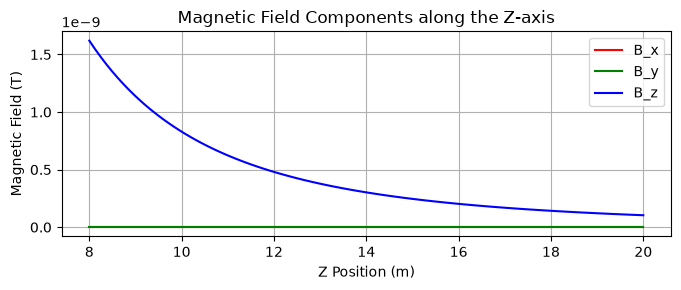

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|8.000000	| 0.000000e+00	| 0.000000e+00	| 1.620022e-09	|
|9.333333	| 0.000000e+00	| 0.000000e+00	| 1.020189e-09	|
|10.666667	| 0.000000e+00	| 0.000000e+00	| 6.834469e-10	|
|12.000000	| 0.000000e+00	| 0.000000e+00	| 4.800066e-10	|
|13.333333	| 0.000000e+00	| 0.000000e+00	| 3.499248e-10	|
|14.666667	| 0.000000e+00	| 0.000000e+00	| 2.629037e-10	|
|16.000000	| 0.000000e+00	| 0.000000e+00	| 2.025028e-10	|
|17.333333	| 0.000000e+00	| 0.000000e+00	| 1.592739e-10	|
|18.666667	| 0.000000e+00	| 0.000000e+00	| 1.275236e-10	|
|20.000000	| 0.000000e+00	| 0.000000e+00	| 1.036814e-10	|


In [9]:
# 测试在线圈正上方8~20m的磁场感应强度
points = np.array([[0, 0, z] for z in np.linspace(8, 20, 100)])
b_field = ug_coil_default.calculate_magnetic_field(points)

plt.figure(figsize=(7, 3))
plt.plot(points[:, 2], b_field[:, 0], label='B_x', color='r')
plt.plot(points[:, 2], b_field[:, 1], label='B_y', color='g')
plt.plot(points[:, 2], b_field[:, 2], label='B_z', color='b')
plt.xlabel('Z Position (m)')
plt.ylabel('Magnetic Field (T)')
plt.title('Magnetic Field Components along the Z-axis')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for z in np.linspace(8, 20, 10):
    b_field = ug_coil_default.calculate_magnetic_field(np.array([0, 0, z]))
    print(f"|{z:.6f}\t| {b_field[0]:.6e}\t| {b_field[1]:.6e}\t| {b_field[2]:.6e}\t|")

Maxwell在土壤中的仿真结果如下（Distance 0m表示实际距离为8m）：

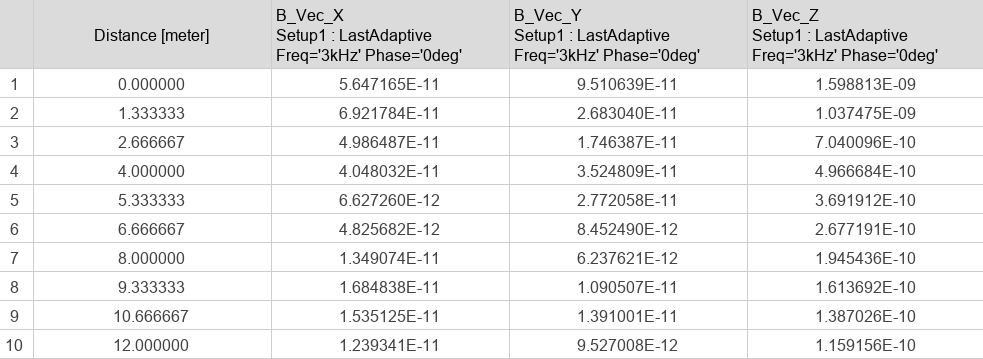

Maxwell在自由空间下的仿真结果如下：

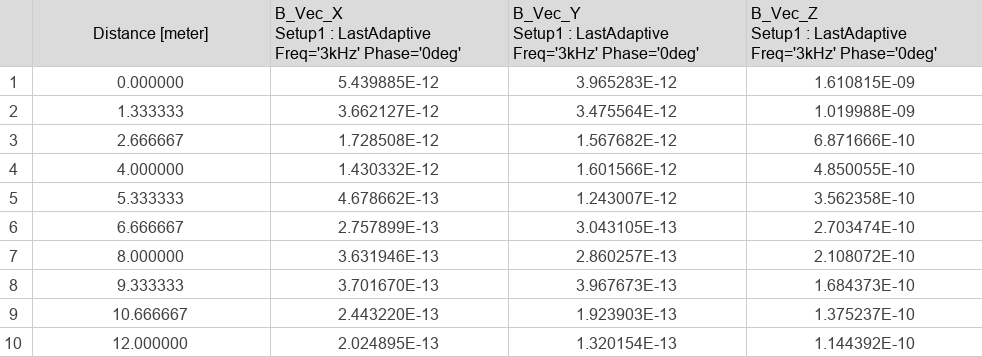

土壤对磁场还是有一定衰减影响的，但是衰减不多（大约在10%以内）。而理论计算的磁场强度在距离较远的时候明显小于Maxwell的仿真结果，这可能是Maxwell仿真边界条件的影响，由于上边界为切向为0的边界条件，这导致了更多的磁感线被扭曲到了Z轴的方向上。至少可以说明的是：纯理论计算是可靠的。

但是值得注意的是，如果线圈的长径比过小，上述的拟合公式会失效，因此仍然需要仿真来提供一个补偿因子以补偿掉理论计算中错误计算的等效介磁系数。

比如说在下列参数中：

| 参数 | 数值 |
| --- | --- |
| 线圈内半径 | 0.035 m |
| 线圈径宽 | 0.005 m |
| 线圈长度 | 0.03 m |
| 磁棒内半径 | 0.032 m |

理论计算的介磁系数需要乘以1.1以补偿掉线圈长径比过小导致的误差。

### 接收区域略微偏心的影响

我们将接收区域向x方向偏移1米，重新计算磁场强度，结果如下：

In [10]:
print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for z in np.linspace(8, 20, 10):
    b_field = ug_coil_default.calculate_magnetic_field(np.array([1, 0, z]))
    print(f"|{z:.6f}\t| {b_field[0]:.6e}\t| {b_field[1]:.6e}\t| {b_field[2]:.6e}\t|")

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|8.000000	| 2.922058e-10	| 0.000000e+00	| 1.546256e-09	|
|9.333333	| 1.593464e-10	| 0.000000e+00	| 9.857978e-10	|
|10.666667	| 9.402999e-11	| 0.000000e+00	| 6.657193e-10	|
|12.000000	| 5.897167e-11	| 0.000000e+00	| 4.701353e-10	|
|13.333333	| 3.881835e-11	| 0.000000e+00	| 3.440816e-10	|
|14.666667	| 2.657791e-11	| 0.000000e+00	| 2.592689e-10	|
|16.000000	| 1.880050e-11	| 0.000000e+00	| 2.001470e-10	|
|17.333333	| 1.366929e-11	| 0.000000e+00	| 1.576934e-10	|
|18.666667	| 1.017428e-11	| 0.000000e+00	| 1.264316e-10	|
|20.000000	| 7.727718e-12	| 0.000000e+00	| 1.029074e-10	|


Maxwell在土壤中的仿真结果如下（Distance 0m表示实际距离为8m）：

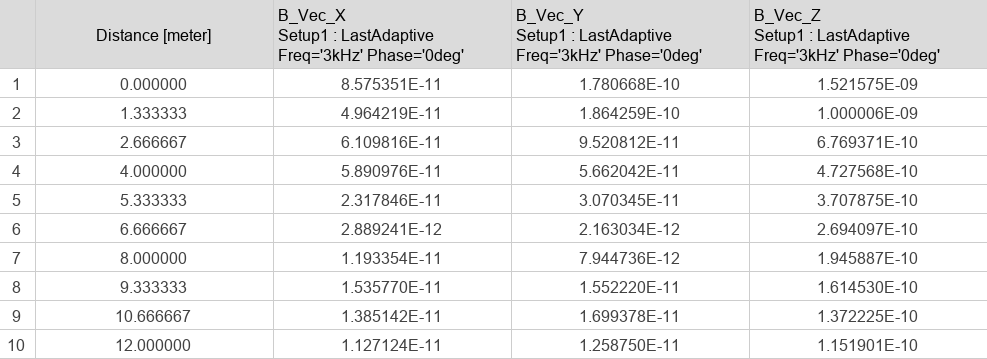

结果表明，只要大致还在雷管的上方，磁场强度的变化不大，因此雷管的接收区域可以略微偏心。
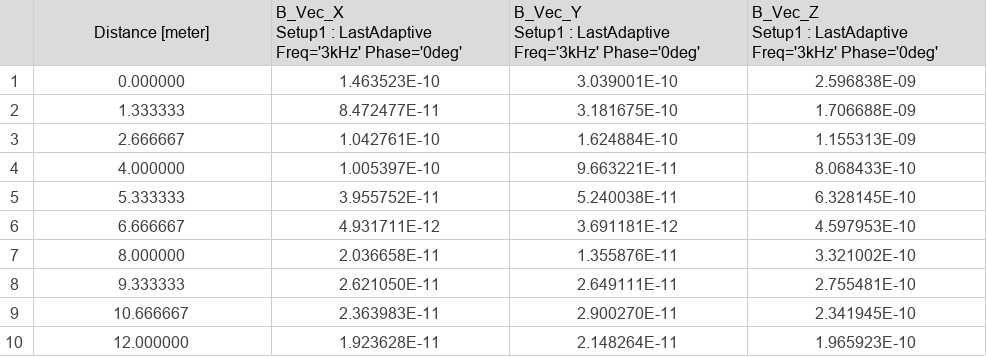

### 土壤对线圈电感的影响

我们将雷管的线圈埋在土中/放置在自由空间中，使用Winding端口计算线圈的电感值，测试频率5kHz，结果如下：

| 雷管位置 | 电阻（Ohm） | 电感（mH） |
| --- | --- | --- |
| 土中 | 2.566 | 198.85 |
| 自由空间 | 2.732 | 199.1 |
| 理论 | 2.521 | 208.46 |

土中的电阻稍微低一点，经过电流密度分析，这主要是因为土壤本身的导电性提供了一定的电流分流路径，导致线圈的总电阻降低。在实际情况中，雷管的线圈应当是和土壤完全绝缘的，因此土壤对雷管线圈的电阻影响不大。

如图所示，土壤内存在电流密度：

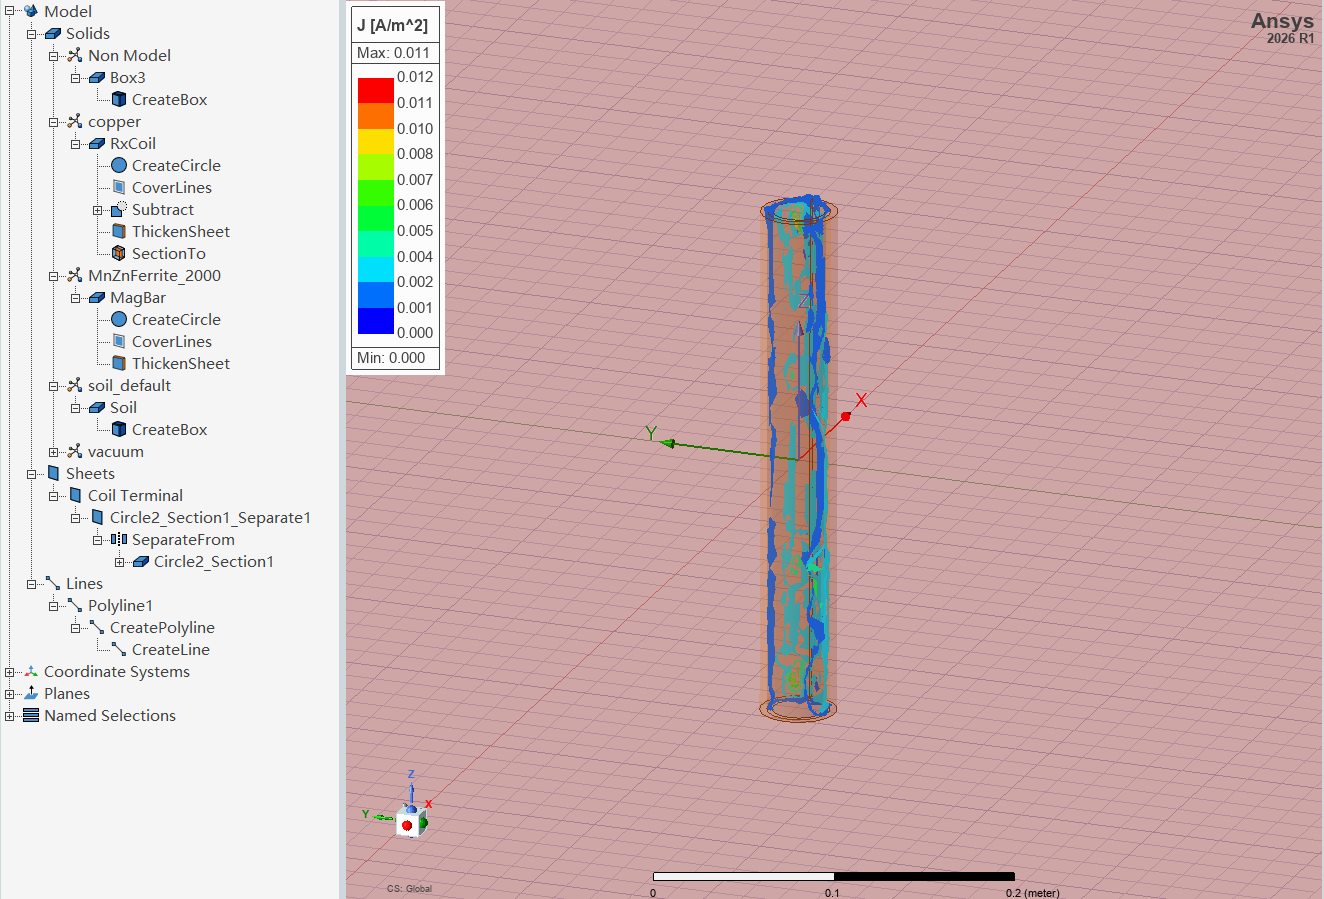

但是一个不得不注意的问题出现了：如此大的电感，在数kHz的0.1A的电流下，线圈两端的电压会非常大，甚至达到数百伏的电压，这对于雷管的绝缘性是一个非常大的挑战。具体的两端电压表示为：
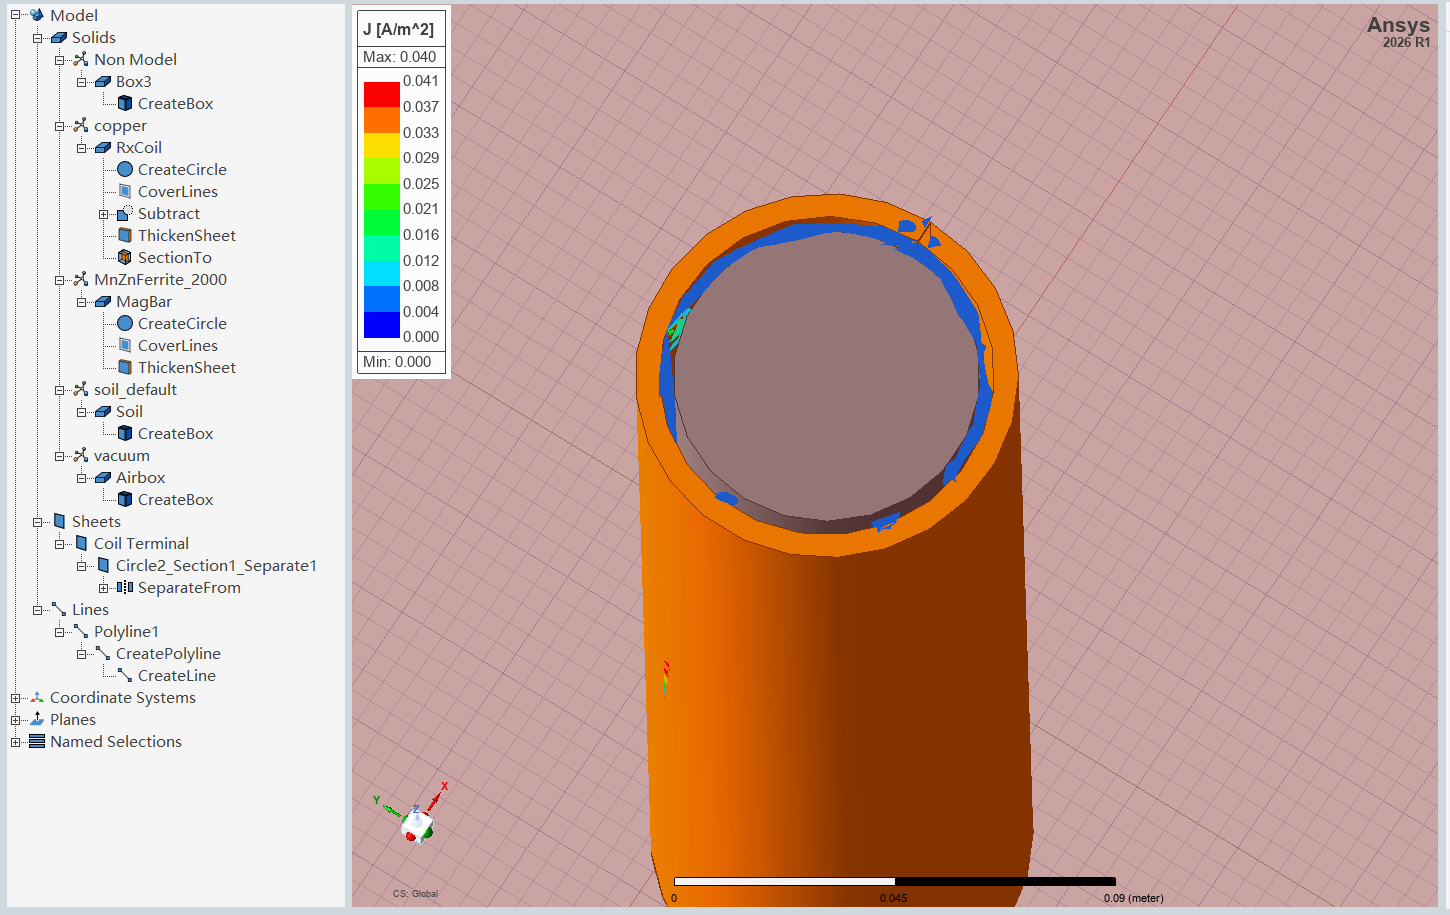

In [15]:
print(f"接收线圈两端的电压为: {ug_coil_default.calculate_resonant_voltage(199.5e-3):.6f} V")

接收线圈两端的电压为: 376.048641 V


这里是一个两难的问题——降低频率可以降低线圈两端的电压，但是会降低磁场的穿透能力；减小线圈的尺寸可以降低线圈的电感，但是会降低磁场的强度。

个人更加倾向于降低频率，因为这样至少还能保证它接收信号的能力。

### 磁芯和线圈半径粗细的影响

我们将磁芯从半径0.005米改变到0.03米，线圈的半径也是从0.005米改变到0.03米（确保磁芯的半径小于线圈的半径），重新计算它们的磁矩，结果如下（仅进行理论计算）：

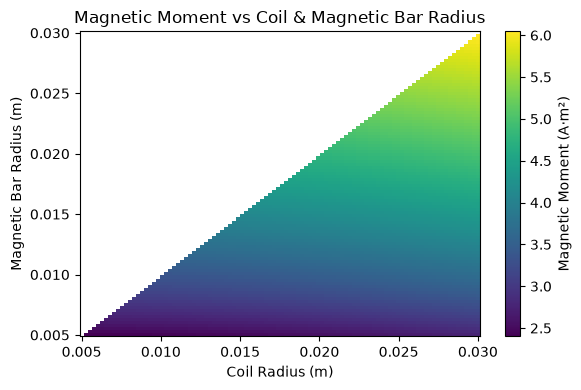

In [12]:
mag_bar_radius = np.linspace(0.005, 0.03, 100)
coil_radius = np.linspace(0.005, 0.03, 100)

# 生成二维网格，coil_radius 作为线圈的内半径
mag_grid, coil_grid = np.meshgrid(mag_bar_radius, coil_radius)

# 计算磁矩，物理约束：磁芯半径必须小于线圈内半径（磁芯要能放进线圈）
mag_moment_grid = np.full(mag_grid.shape, np.nan)
for i in range(mag_grid.shape[0]):
    for j in range(mag_grid.shape[1]):
        r_bar = mag_grid[i, j]
        r_coil = coil_grid[i, j]
        if r_bar >= r_coil:
            continue
        ug_coil = UGCoil(mag_bar_radius=r_bar, inner_radius=r_coil)
        mag_moment_grid[i, j] = ug_coil.mag_moment

# 绘制磁矩随磁芯半径和线圈半径变化的热力图
plt.figure(figsize=(6, 4))
cf = plt.pcolormesh(coil_grid, mag_grid, mag_moment_grid, shading='auto', cmap='viridis')
plt.colorbar(cf, label='Magnetic Moment (A·m²)')
plt.xlabel('Coil Radius (m)')
plt.ylabel('Magnetic Bar Radius (m)')
plt.title('Magnetic Moment vs Coil & Magnetic Bar Radius')
plt.tight_layout()
plt.show()

由此看来，磁芯半径的增大对磁矩的提升有着非常明显的作用。

### 实际距离磁场计算

接下来理论计算在实际距离下的磁场强度（5~20米高处，偏移0.5米），结果如下：

In [13]:
points = np.array([[0.5, 0, z] for z in np.linspace(5, 20, 6)])
ug_coil = UGCoil(current=0.03)
# 设置发射线圈电流为0.03A，避免出现过大的电压
voltage = ug_coil.current * 234.5e-3 * ug_coil.frequency * 2 * np.pi
print(f"发射线圈两端的电压为: {voltage:.6f} V")
b_field = ug_coil.calculate_magnetic_field(points)
h_field = b_field / Const.mu0

print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for idx in range(len(points)):
    print(f"|{points[idx, 2]:.6f}\t| {b_field[idx, 0]:.6e}\t| {b_field[idx, 1]:.6e}\t| {b_field[idx, 2]:.6e}\t|")
print()
print("|Position (m)\t| H_x (A/m)\t| H_y (A/m)\t| H_z (A/m)\t|")
print("|------------\t|----------\t|----------\t|----------\t|")
for idx in range(len(points)):
    print(f"|{points[idx, 2]:.6f}\t| {h_field[idx, 0]:.6e}\t| {h_field[idx, 1]:.6e}\t| {h_field[idx, 2]:.6e}\t|")

发射线圈两端的电压为: 132.606626 V
|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000000	| 2.912661e-10	| 0.000000e+00	| 1.932065e-09	|
|8.000000	| 4.512120e-11	| 0.000000e+00	| 4.803527e-10	|
|11.000000	| 1.268124e-11	| 0.000000e+00	| 1.857994e-10	|
|14.000000	| 4.842586e-12	| 0.000000e+00	| 9.033728e-11	|
|17.000000	| 2.229662e-12	| 0.000000e+00	| 5.051714e-11	|
|20.000000	| 1.164595e-12	| 0.000000e+00	| 3.104617e-11	|

|Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m)	|
|------------	|----------	|----------	|----------	|
|5.000000	| 2.317822e-04	| 0.000000e+00	| 1.537489e-03	|
|8.000000	| 3.590631e-05	| 0.000000e+00	| 3.822526e-04	|
|11.000000	| 1.009141e-05	| 0.000000e+00	| 1.478545e-04	|
|14.000000	| 3.853607e-06	| 0.000000e+00	| 7.188813e-05	|
|17.000000	| 1.774308e-06	| 0.000000e+00	| 4.020026e-05	|
|20.000000	| 9.267556e-07	| 0.000000e+00	| 2.470576e-05	|


## 地面无人车磁发射机分析

地面无人车的磁发射机和地面固定发射机是类似的，只不过地面无人车的磁发射机会更加小一点。考虑到上述分析已经足以说明理论计算的正确性，我们直接给出深度8~20米，偏移0.5米的磁场强度计算结果如下：

In [14]:
tx_uv_coil = UVCoil()
points = np.array([[0.5, 0, z] for z in np.linspace(5, 20, 6)])
b_field = tx_uv_coil.calculate_magnetic_field(points)
h_field = b_field / Const.mu0

print("|Position (m)\t| B_x (T)\t| B_y (T)\t| B_z (T)\t|")
print("|------------\t|--------\t|--------\t|--------\t|")
for idx in range(len(points)):
    print(f"|{points[idx, 2]:.6f}\t| {b_field[idx, 0]:.6e}\t| {b_field[idx, 1]:.6e}\t| {b_field[idx, 2]:.6e}\t|")
print()
print("|Position (m)\t| H_x (A/m)\t| H_y (A/m)\t| H_z (A/m)\t|")
print("|------------\t|----------\t|----------\t|----------\t|")
for idx in range(len(points)):
    print(f"|{points[idx, 2]:.6f}\t| {h_field[idx, 0]:.6e}\t| {h_field[idx, 1]:.6e}\t| {h_field[idx, 2]:.6e}\t|")

|Position (m)	| B_x (T)	| B_y (T)	| B_z (T)	|
|------------	|--------	|--------	|--------	|
|5.000000	| 1.694494e-09	| 0.000000e+00	| 1.124015e-08	|
|8.000000	| 2.625009e-10	| 0.000000e+00	| 2.794541e-09	|
|11.000000	| 7.377546e-11	| 0.000000e+00	| 1.080922e-09	|
|14.000000	| 2.817264e-11	| 0.000000e+00	| 5.255538e-10	|
|17.000000	| 1.297147e-11	| 0.000000e+00	| 2.938928e-10	|
|20.000000	| 6.775249e-12	| 0.000000e+00	| 1.806168e-10	|

|Position (m)	| H_x (A/m)	| H_y (A/m)	| H_z (A/m)	|
|------------	|----------	|----------	|----------	|
|5.000000	| 1.348436e-03	| 0.000000e+00	| 8.944624e-03	|
|8.000000	| 2.088916e-04	| 0.000000e+00	| 2.223825e-03	|
|11.000000	| 5.870865e-05	| 0.000000e+00	| 8.601706e-04	|
|14.000000	| 2.241907e-05	| 0.000000e+00	| 4.182224e-04	|
|17.000000	| 1.032237e-05	| 0.000000e+00	| 2.338724e-04	|
|20.000000	| 5.391572e-06	| 0.000000e+00	| 1.437303e-04	|


## 总结

本文基于 Ansys Maxwell 仿真与自由空间磁偶极子理论计算，联合分析了地面磁发射机与地下雷管线圈的磁场特性。主要结论如下：

### 一、地面发射线圈

**1. 自由空间磁偶极子公式可用。** 无土壤时理论值与 Maxwell 仿真误差在 5% 以内，带土壤（σ = 0.005 S/m）时误差约 5%～10%，因此在低电导率土壤下可直接用磁偶极子公式快速估算，无需每次仿真。

**2. 土壤的影响有限。** 土壤对磁场分布仅有约 10% 以内的衰减，对线圈电感的影响在 0.1% 以内（线圈立起、平躺均如此）。土壤导电性会使电阻略降，但那是土壤提供的分流路径所致，实际雷管线圈与土壤绝缘，可忽略该影响。

**3. 发射线圈宜平躺布置。** 线圈平面平行于地面（与雷管线圈朝向一致）时，磁场约有 7 倍增益，尤其适合"雷管到线圈水平距离远大于垂直距离"的实际工况。

**4. 实际工作距离下场强为 pT 量级。** 在 200～300 m 距离处磁场约 10⁻¹² T（平躺时 B_z 约 −7.9×10⁻¹² ～ −2.4×10⁻¹² T）。

### 二、地下雷管线圈

**5. 理论计算可靠，但需注意边界条件与长径比。** 纯理论计算是可靠的；但 Maxwell 采用"上边界切向为零"的边界条件，会把磁感线扭曲到 Z 方向，导致远距离时理论值明显小于仿真值。当线圈长径比过小时，等效磁导率拟合公式失效，需用仿真给出补偿因子（如某参数下需将理论介磁系数乘以 1.1）。

**6. 接收区域可略微偏心。** 只要大致位于雷管正上方（如偏移 1 m），磁场强度变化不大。

**7. 主要隐患是线圈两端的感应电压。** 雷管线圈电感约 200 mH，在工作频率、0.1 A 电流下两端电压可达约 375 V，对绝缘构成挑战。此为两难：降低频率可降电压但削弱穿透能力，减小尺寸可降电感但削弱磁场强度。作者更倾向于降低频率，以保证接收信号的能力。

**8. 尽量增大磁芯半径。** 磁场强度随磁芯半径和线圈半径增长，应尽可能增大磁芯半径。